# Kantenorientierte Segmentierung

Objekte über ihre **Grenzen** finden: Eine Kante ist eine Stelle mit großem Gradientenbetrag (VL 4)

$$G = \sqrt{G_x^2 + G_y^2}$$

**Wo Sie etwas ergänzen müssen, steht `# TODO`.**

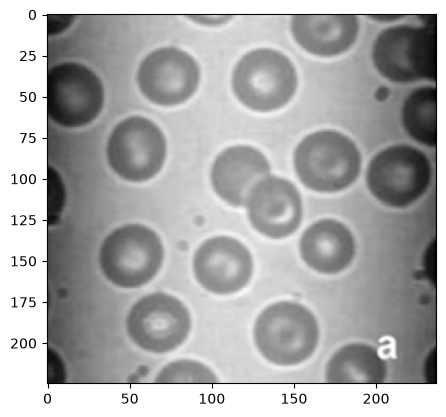

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

L = 256
img = cv2.imread('zellen.png', 0)   # 0 = als Graustufenbild laden
plt.imshow(img, cmap='gray')

## 1 Parallele Kantenextraktion

Jedes Pixel wird einzeln geprüft: Gehört es zu einer Kante?

**Schritt 1:** Bild glätten, damit Rauschen keine Kanten erzeugt → `cv2.GaussianBlur(bild, (5, 5), 1.5)`

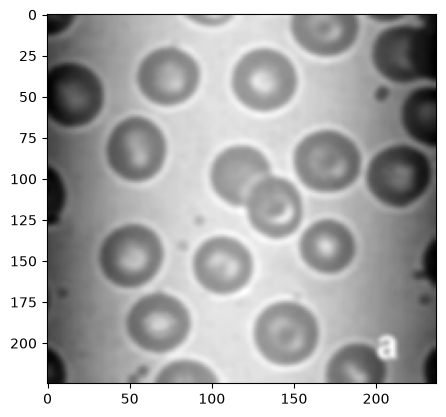

In [3]:
img_s = cv2.GaussianBlur(img, (5, 5), 1.5)   # TODO: Gauß-Filter

plt.imshow(img_s, cmap='gray')

**Schritt 2:** Sobel in x- und y-Richtung, daraus der Gradientenbetrag $G$.
Damit wir $t$ wie gewohnt wählen können, bringen wir $G$ danach auf $[0, L-1]$.

Tipp: `cv2.Sobel(bild, cv2.CV_64F, 1, 0)` ergibt $G_x$, `cv2.Sobel(bild, cv2.CV_64F, 0, 1)` ergibt $G_y$.

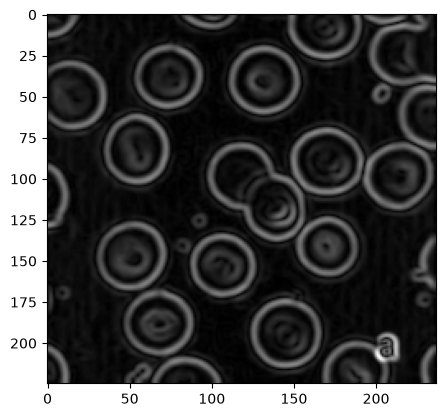

In [4]:
Gx = cv2.Sobel(img_s, cv2.CV_64F, 1, 0, ksize=3)   # TODO: Sobel in x-Richtung
Gy = cv2.Sobel(img_s, cv2.CV_64F, 0, 1, ksize=3)   # TODO: Sobel in y-Richtung
G = np.sqrt(Gx**2 + Gy**2)    # TODO: Gradientenbetrag

G = (L-1) * G / G.max()   # auf 0 ... L-1 skalieren
plt.imshow(G, cmap='gray')

**Schritt 3:** Schwellwert auf $G$: Kantenpixel, falls $G > t$ (wie in VL 5).

**Aufgabe:** Probieren Sie verschiedene $t$ aus. Was passiert bei zu kleinem, was bei zu großem $t$?

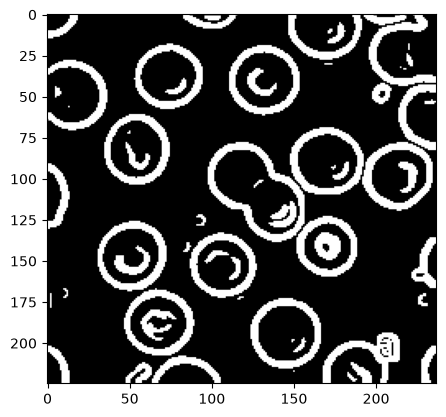

In [8]:
t = 50   # TODO: Schwellwert wählen
_, img_t = cv2.threshold(G, t, L-1, cv2.THRESH_BINARY)
img_t = img_t.astype(np.uint8)

plt.imshow(img_t, cmap='gray')

*Ihre Antworten:*

1. zu kleines t: alles Hell
2. zu großes t: alles Dunkel

**Schritt 4:** Einzelne Störpixel entfernen → Medianfilter `cv2.medianBlur(bild, 3)` (VL 4)

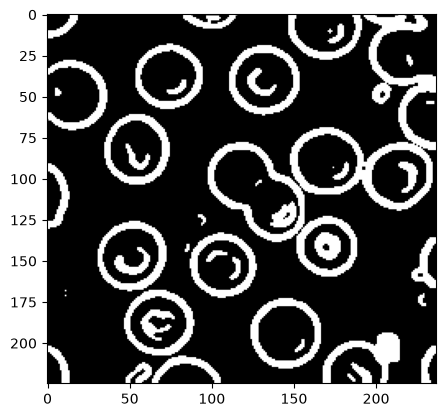

In [11]:
img_final = cv2.medianBlur(img_t, 3)   # TODO: Medianfilter

plt.imshow(img_final, cmap='gray')

**Zum Vergleich: Canny.** In der Praxis nimmt man meist den Canny-Detektor. Er liefert 1 Pixel dünne Kanten. Achtung: `cv2.Canny` glättet nicht selbst, deshalb nehmen wir das geglättete Bild.

**Aufgabe:**
1. Vergleichen Sie mit Ihrem Ergebnis. Was ist anders?
2. Sind alle Konturen geschlossen? Lassen sich die beiden Zellen trennen, die sich in der Mitte berühren?

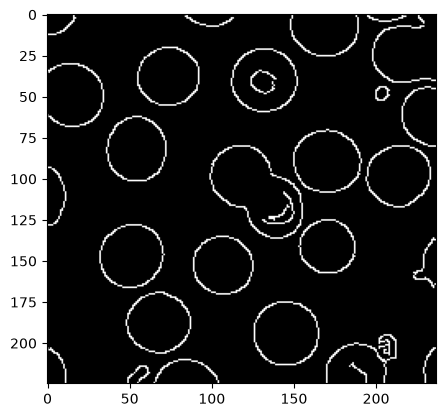

In [12]:
img_canny = cv2.Canny(img_s, 50, 150)

plt.imshow(img_canny, cmap='gray')

*Ihre Antworten:*

1. Kanten sind feiner / dünner
2. Mehr Störpixel werden gelöscht (genauer)

## 2 Wasserscheidentransformation mit Markern

Ohne Marker wird jedes kleine Minimum ein eigenes Becken → Übersegmentierung (Folie 8).
Deshalb geben wir **Marker** vor: einen je Tablette und einen für den Hintergrund.

`cv2.watershed` braucht ein Farbbild und ein Markerbild:
- `1` = sicher Hintergrund
- `2, 3, …` = sicher Tablette (eine Nummer je Tablette)
- `0` = unbekannt → hier wird geflutet, hier entstehen die Dämme

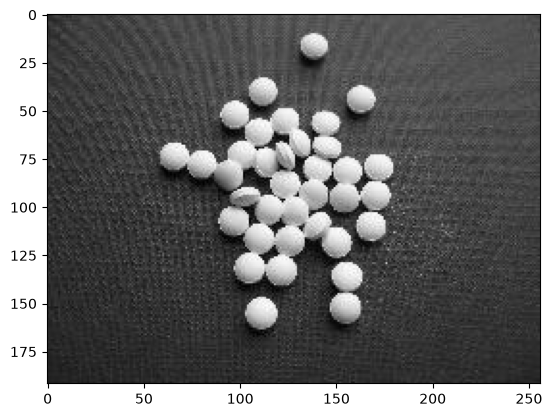

In [14]:
img = cv2.imread('pills.png')[:, :, ::-1].copy()   # BGR -> RGB
img_g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
plt.imshow(img_g, cmap='gray')

**Schritt 1:** Tabletten grob finden mit Otsu (VL 5). Danach einzelne Störpixel mit einem Opening entfernen (VL 4).

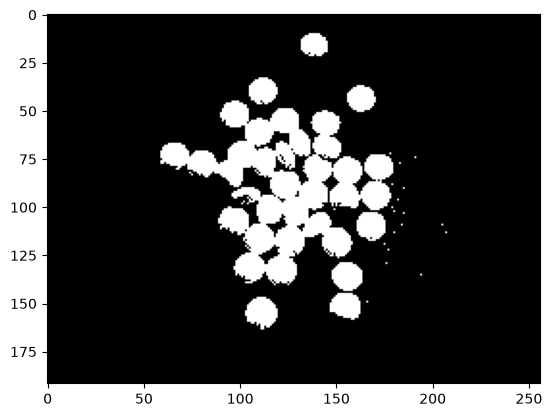

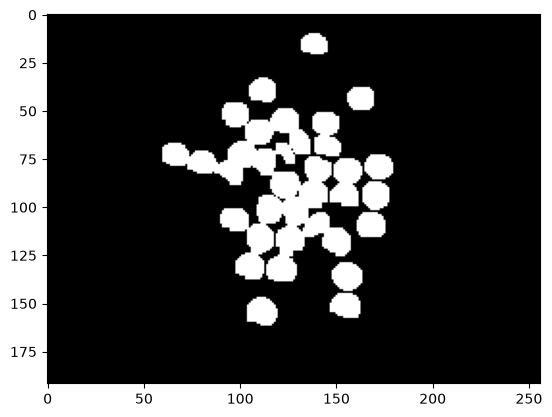

In [16]:
_, img_t = cv2.threshold(img_g, 0, L-1, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
plt.imshow(img_t, cmap='gray')
plt.show()

k = np.ones((3, 3), np.uint8)
img_o = cv2.morphologyEx(img_t, cv2.MORPH_OPEN, k, iterations=2)   # TODO: Opening mit k, 2 Iterationen
plt.imshow(img_o, cmap='gray')

**Schritt 2:** Was ist *sicher* Tablette, was *sicher* Hintergrund?
- Erosion verkleinert die Tabletten → was übrig bleibt, ist sicher Tablette (`img_fg`)
- Dilatation vergrößert die Tabletten → was außerhalb liegt, ist sicher Hintergrund (`img_bg`)
- Dazwischen liegt der unsichere Rand: `img_bg - img_fg` (das ist der morphologische Gradient aus VL 4)

Tipp: `cv2.erode(bild, k, iterations=4)` und `cv2.dilate(bild, k, iterations=4)`

Text(0.5, 1.0, 'unsicherer Rand')

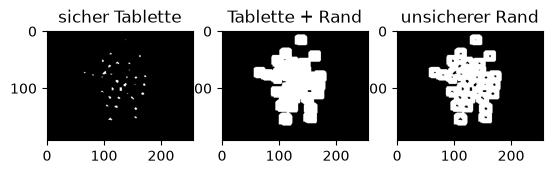

In [17]:
img_fg = cv2.erode(img_o, k, iterations=4)       # TODO: Erosion
img_bg = cv2.dilate(img_o, k, iterations=4)       # TODO: Dilatation
img_rand = img_bg - img_fg     # TODO: unsicherer Rand

plt.subplot(1, 3, 1); plt.imshow(img_fg, cmap='gray'); plt.title('sicher Tablette')
plt.subplot(1, 3, 2); plt.imshow(img_bg, cmap='gray'); plt.title('Tablette + Rand')
plt.subplot(1, 3, 3); plt.imshow(img_rand, cmap='gray'); plt.title('unsicherer Rand')

**Schritt 3:** Markerbild bauen. `cv2.connectedComponents` nummeriert jede zusammenhängende Fläche: Hintergrund 0, Tabletten 1, 2, 3, …
Wir zählen 1 dazu (Hintergrund = 1) und setzen den unsicheren Rand auf 0.

Anzahl Marker (Tabletten): 33


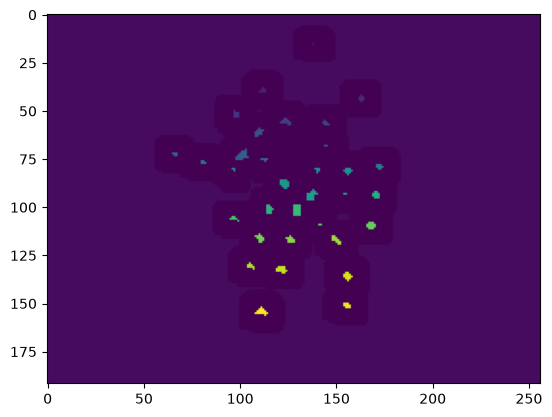

In [18]:
anzahl, markers = cv2.connectedComponents(img_fg)
markers = markers + 1
markers[img_rand == L-1] = 0

print('Anzahl Marker (Tabletten):', anzahl - 1)
plt.imshow(markers)

**Schritt 4:** Wasserscheide berechnen. Ergebnis: jede Region hat ihre Nummer, die Dämme (Wasserscheiden) haben den Wert $-1$.

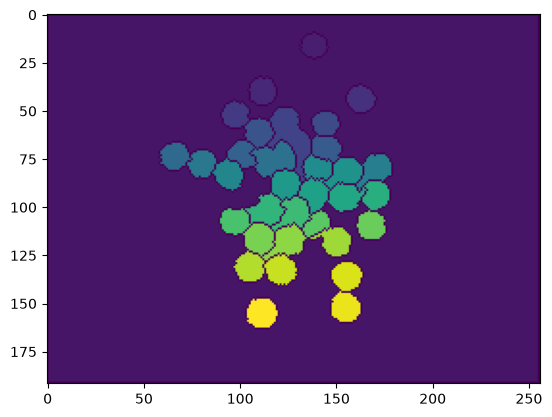

In [20]:
img_ws = cv2.watershed(img, markers)   # TODO: cv2.watershed(farbbild, markers)

plt.imshow(img_ws)

Die Dämme ($-1$) rot ins Originalbild einzeichnen:

**Aufgabe:** Bekommt jede Tablette einen eigenen Marker? Was passiert mit zwei Tabletten, die nur einen gemeinsamen Marker haben?

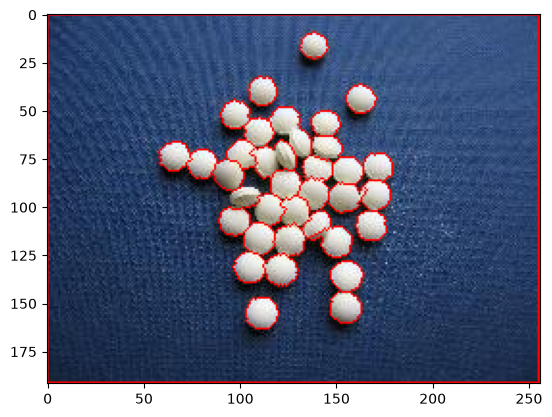

In [21]:
img[img_ws == -1] = [255, 0, 0]
plt.imshow(img)

*Ihre Antworten:*
werden zusammengefürt und als eine Tablette betrachtet
